# <center> Data Preprocessing With Inspiration from xG Paper <center>

### Features: 

At each time-step (row), the dataset will contain:

- Relevant ball data (positions, speed)

- Distance of the ball to the center of the goal (3D center)

- Angle of the ball between the goal posts (coordinates above)

- Number of opposing players between the ball and the goal (number of players in the "shot triangle")

- Make a "team state" variable for each team (attacking team and defending team) to encode the overall structure/dynamics of the team via a Spectral Embedding, and take the Fiedler vector for a 1D representation. Add each team's centroid's distances to the ball state

- Using the "real" units, make for both teams a column for each xyz centroid, and add a column for each teams' centroids' distances to the ball

Then, split the data into a "real units" dataset and a "spectral embedding" dataset. The finalized datasets will be saved in the `datasets` file directory.

### Important Notes:

- Goal dimensions: 2000 units wide x 456 units tall. Blue goal at y = -5200, x $\in$ [-1000,1000]; Orange goal at y = 5200, x $\in$ [-1000,1000]

- Blue team half is when $\text{pos}_y < 0$. Orange team half is when $\text{pos}_y > 0$

---

## Preprocessing Steps:

### Step 1:

Separate relevant ball data into its own dataframe (will be the principle dataframe post-separation)

### Step 2: 

Using the new principle dataframe, for each time-step compute the 3D distance of the ball to the center of the goal and the angle of the ball between the goal-posts

### Step 3:

Using the new angle variable, use the player positions of the defending team to determine (at each time-step) how many of them are betweeen the ball and the goal

### Step 4:

Find the number of players within 400 units of the ball

### Step 5:

Implement a Spectral Embedding on the attacking and defending teams, respectively, to get a team-state variable; add a column for each team's state's distance to the ball state

### Step 6:

Using the "real" units, make for both teams a column for each xyz centroid, and add a column for each teams' centroids' distances to the ball

### Step 7:

Once all the new features are created, standardize/scale the features appropriately for use with a model. Add the label into the final dataset

### Step 8:

Select only the first 32 frames of each segment instead of 64

### Step 9:

Turn the dataframes into separate torch tensors, merge into a torch dataset, and save the dataset

---

In [1]:
import pandas as pd
import numpy as np
import os

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [2]:
DATA_DIR = '/Users/marcomaluf/Desktop/Unfinished Projects/paper/training_replays_csvs'
SAVE_DIR = '/Users/marcomaluf/Desktop/Unfinished Projects/paper/training_preprocessed_data'
raw_csvs = os.listdir(DATA_DIR)

In [3]:
# initial preprocessing testing used raw_csvs[4]

# sample_df = pd.read_csv(f'{DATA_DIR}/{raw_csvs[4]}').drop(columns='Unnamed: 0') 
sample_df = pd.read_csv('/Users/marcomaluf/Desktop/Unfinished Projects/paper/training_replays_csvs/2025-01-10.15.41 Millsy Ranked Standard Win.csv').drop(columns='Unnamed: 0') 
sample_df

,pos_x,pos_y,pos_z,vel_x,vel_y,vel_z,hit_team_no,pos_x.1,pos_y.1,pos_z.1,...,pos_y.6,pos_z.6,vel_x.6,vel_y.6,vel_z.6,boost_active.5,team.5,dist_to_ball.5,label,base_df_index
0,-2150.14,2238.17,1281.83,0.0,0.0,0.0,-1.0,-2451.20,2108.84,936.27,...,3471.75,17.01,0.0,0.0,2.7,False,1,2882.177461,0,847
1,-2121.76,2260.65,1265.37,0.0,0.0,0.0,-1.0,-2357.67,2176.82,928.22,...,3671.79,17.01,0.0,0.0,2.7,False,1,2906.257972,0,848
2,-2093.41,2283.11,1248.21,0.0,0.0,0.0,-1.0,-2357.67,2176.82,928.22,...,3671.79,17.01,0.0,0.0,2.7,False,1,2866.398167,0,849
3,-2072.17,2299.94,1234.88,0.0,0.0,0.0,-1.0,-2357.67,2176.82,928.22,...,3671.79,17.01,0.0,0.0,2.7,False,1,2836.333383,0,850
4,-2029.73,2333.56,1207.03,0.0,0.0,0.0,-1.0,-2258.31,2244.73,921.12,...,3902.20,17.01,0.0,0.0,2.7,False,1,2847.149314,0,851
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1083,553.23,-5208.96,152.42,9503.8,12213.9,4409.0,0.0,216.49,-3691.70,79.69,...,-4806.78,16.99,1901.8,-11020.5,7351.7,True,1,1041.306807,1,12825
1084,513.08,-5215.44,151.18,9488.9,12195.3,4077.2,0.0,216.49,-3691.70,79.69,...,-4816.89,16.99,1858.6,-10943.9,7195.9,False,1,881.296669,1,12826
1085,513.08,-5215.44,151.18,9481.7,12186.0,3911.6,0.0,400.41,-3786.63,79.53,...,-4818.54,16.99,1857.9,-10940.3,7096.8,False,1,854.023022,1,12827
1086,513.08,-5215.44,151.18,9472.1,12173.6,3690.8,0.0,400.41,-3786.63,79.53,...,-4818.54,16.99,1857.9,-10940.3,7096.8,False,1,854.023022,1,12828


In [4]:
sample_df.info(verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 1088 entries, 0 to 1087
Data columns (total 63 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   pos_x           1088 non-null   float64
 1   pos_y           1088 non-null   float64
 2   pos_z           1088 non-null   float64
 3   vel_x           1088 non-null   float64
 4   vel_y           1088 non-null   float64
 5   vel_z           1088 non-null   float64
 6   hit_team_no     1088 non-null   float64
 7   pos_x.1         1088 non-null   float64
 8   pos_y.1         1088 non-null   float64
 9   pos_z.1         1088 non-null   float64
 10  vel_x.1         1088 non-null   float64
 11  vel_y.1         1088 non-null   float64
 12  vel_z.1         1088 non-null   float64
 13  boost_active    1088 non-null   bool   
 14  team            1088 non-null   int64  
 15  dist_to_ball    1088 non-null   float64
 16  pos_x.2         1088 non-null   float64
 17  pos_y.2         1088 non-null   float64
 18 

In [5]:
print(sample_df.isna().sum().to_frame().to_markdown())

|                |   0 |
|:---------------|----:|
| pos_x          |   0 |
| pos_y          |   0 |
| pos_z          |   0 |
| vel_x          |   0 |
| vel_y          |   0 |
| vel_z          |   0 |
| hit_team_no    |   0 |
| pos_x.1        |   0 |
| pos_y.1        |   0 |
| pos_z.1        |   0 |
| vel_x.1        |   0 |
| vel_y.1        |   0 |
| vel_z.1        |   0 |
| boost_active   |   0 |
| team           |   0 |
| dist_to_ball   |   0 |
| pos_x.2        |   0 |
| pos_y.2        |   0 |
| pos_z.2        |   0 |
| vel_x.2        |   0 |
| vel_y.2        |   0 |
| vel_z.2        |   0 |
| boost_active.1 |   0 |
| team.1         |   0 |
| dist_to_ball.1 |   0 |
| pos_x.3        |   0 |
| pos_y.3        |   0 |
| pos_z.3        |   0 |
| vel_x.3        |   0 |
| vel_y.3        |   0 |
| vel_z.3        |   0 |
| boost_active.2 |   0 |
| team.2         |   0 |
| dist_to_ball.2 |   0 |
| pos_x.4        |   0 |
| pos_y.4        |   0 |
| pos_z.4        |   0 |
| vel_x.4        |   0 |


## Step 1:

In [6]:
speed = np.sqrt(np.sum([
    np.power(sample_df.vel_x.values.astype(float), 2),
    np.power(sample_df.vel_y.values.astype(float), 2),
    np.power(sample_df.vel_z.values.astype(float), 2)
], axis=0))

ball_data = sample_df[['pos_x', 'pos_y', 'pos_z']].copy(deep=True)
ball_data.loc[:,'speed'] = speed
ball_data = ball_data.astype(float)
ball_data

,pos_x,pos_y,pos_z,speed
0,-2150.14,2238.17,1281.83,0.000000
1,-2121.76,2260.65,1265.37,0.000000
2,-2093.41,2283.11,1248.21,0.000000
3,-2072.17,2299.94,1234.88,0.000000
4,-2029.73,2333.56,1207.03,0.000000
...,...,...,...,...
1083,553.23,-5208.96,152.42,16091.639091
1084,513.08,-5215.44,151.18,15980.867471
1085,513.08,-5215.44,151.18,15928.020764
1086,513.08,-5215.44,151.18,15859.988020


## Step 2:

In [7]:
final_value = []
for i in range(64, ball_data.shape[0]+1, 64):
    final_value.append(ball_data['pos_y'].iloc[i-1])
    
half = np.where(np.array(final_value) <= 0, 0, 1)

In [8]:
blue_goal_center = np.array([0, -5200, 273])
orange_goal_center = np.array([0, 5200, 273])

def distance_3d(v1, v2):
    d = np.power(v1-v2, 2)
    d = np.sum(d, axis=1)

    distance = np.sqrt(d)
    
    return distance

segments = [ball_data[['pos_x', 'pos_y', 'pos_z']].iloc[i:i+64] for i in range(0, ball_data.shape[0], 64)]

In [9]:
for seg, h in zip(segments, half):
    if h == 0:
        d = distance_3d(seg, blue_goal_center)
        seg['distance_to_goal'] = d
    else:
        d = distance_3d(seg, orange_goal_center)
        seg['distance_to_goal'] = d

In [10]:
dist_to_goal = pd.concat(segments, ignore_index=True)
dist_to_goal = dist_to_goal['distance_to_goal']
ball_data.loc[:, 'dist_to_goal'] = dist_to_goal.values
ball_data

,pos_x,pos_y,pos_z,speed,dist_to_goal
0,-2150.14,2238.17,1281.83,0.000000,3796.482179
1,-2121.76,2260.65,1265.37,0.000000,3758.515949
2,-2093.41,2283.11,1248.21,0.000000,3720.436432
3,-2072.17,2299.94,1234.88,0.000000,3691.808452
4,-2029.73,2333.56,1207.03,0.000000,3634.376726
...,...,...,...,...,...
1083,553.23,-5208.96,152.42,16091.639091,566.289017
1084,513.08,-5215.44,151.18,15980.867471,527.569514
1085,513.08,-5215.44,151.18,15928.020764,527.569514
1086,513.08,-5215.44,151.18,15859.988020,527.569514


In [11]:
def ball_goal_angle(a, b = np.array([-1000, 5200]), c = np.array([1000, 5200])):
    # a := ball 2d position, b := left post, c := right post
    a = a.copy()  
    a['pos_y'] = np.abs(a['pos_y'])
    a = a[['pos_x', 'pos_y']].values  

    ab = b - a
    ac = c - a
    dot = np.einsum('ij,ij->i', ab, ac) 

    mag_ab = np.linalg.norm(ab, axis=1)
    mag_ac = np.linalg.norm(ac, axis=1)

    theta = np.degrees(np.arccos(dot / (mag_ab * mag_ac)))

    return theta  

In [12]:
angle_to_goal = ball_goal_angle(a=ball_data[['pos_x', 'pos_y']])
ball_data.loc[:, 'angle_to_goal'] = angle_to_goal
ball_data

,pos_x,pos_y,pos_z,speed,dist_to_goal,angle_to_goal
0,-2150.14,2238.17,1281.83,0.000000,3796.482179,25.542503
1,-2121.76,2260.65,1265.37,0.000000,3758.515949,25.835180
2,-2093.41,2283.11,1248.21,0.000000,3720.436432,26.133522
3,-2072.17,2299.94,1234.88,0.000000,3691.808452,26.361052
4,-2029.73,2333.56,1207.03,0.000000,3634.376726,26.826215
...,...,...,...,...,...,...
1083,553.23,-5208.96,152.42,16091.639091,566.289017,178.520569
1084,513.08,-5215.44,151.18,15980.867471,527.569514,177.599141
1085,513.08,-5215.44,151.18,15928.020764,527.569514,177.599141
1086,513.08,-5215.44,151.18,15859.988020,527.569514,177.599141


## Step 3:

(find the number of defending players in-between the ball and the goal [in the 2D-triangle and with z <= 646, halfway between the floor and the ceiling])

### Algorithm for Step 3:

1. determine which half the play is on (use the `half` array from **Step 2**)
2. For each time_step in the segment:
    - record the ball's xy-position, and each defending player's xyz-position
    - if the defending players `pos_z` <= 646, check if they are in the triangle with the function
    - if yes, count += 1
    - return the count for that time-step

In [13]:
def sign(p1, p2, p3):
    """Computes the cross product sign for all timesteps."""
    result = (p1[:, 0] - p3[:, 0]) * (p2[:, 1] - p3[:, 1]) - (p2[:, 0] - p3[:, 0]) * (p1[:, 1] - p3[:, 1])
    return result

def is_player_inside_ball_goal_triangle(player_pos, ball_position, half):

    # Define goalpost positions based on which half
    if half == 0:
        p_left = np.array([-1000, -5200, 646])  # Left goalpost
        p_right = np.array([1000, -5200, 646])  # Right goalpost
    else:
        p_left = np.array([-1000, 5200, 646])
        p_right = np.array([1000, 5200, 646])
    
    # Ensure inputs are NumPy arrays
    player_pos = np.asarray(player_pos)  # Shape (N, 3)
    ball_position = np.asarray(ball_position)  # Shape (N, 3)
    
    # Expand goalpost positions to match shape (N, 3)
    p_left = np.tile(p_left, (player_pos.shape[0], 1))   # (N, 3)
    p_right = np.tile(p_right, (player_pos.shape[0], 1))  # (N, 3)
    
    # Compute signs for the three edges of the triangle
    s1 = sign(player_pos, ball_position, p_left)
    s2 = sign(player_pos, p_left, p_right)
    s3 = sign(player_pos, p_right, ball_position)
    
    inside = ((s1>=0) & (s2>=0) & (s3>=0)) | ((s1<=0) & (s2<=0) & (s3<=0))
    return inside

In [14]:
player_positions_indeces = [7,8,9,14, 16,17,18,23, 25,26,27,32, 34,35,36,41, 43,44,45,50, 52,53,54,59]
player_segments = [sample_df.iloc[i:i+64, player_positions_indeces].copy(deep=True) for i in range(0, sample_df.shape[0], 64)]

In [15]:
players_btwn_ball_and_goal = []

for ball, players, h in zip(segments, player_segments, half):
    temp = []
    
    # Identify player indices (assuming 4 columns per player: x, y, z, team)
    num_players = players.shape[1] // 4  
    selected_columns = []  

    for i in range(num_players):
        team_col = i * 4 + 3  # The "team" column index for player i
        
        # Keep players whose team is NOT on the ball's half
        if not (players.iloc[:, team_col] == h).all():
            selected_columns.extend(players.columns[i * 4: i * 4 + 4])

    # Filter the DataFrame
    players = players[selected_columns]

    # Iterate over each player and check if they are inside the ball-goal triangle
    for i in range(0, players.shape[1] - 3, 4):  # Step by 4 to get x, y, z
        player = players.iloc[:, i:i+3]  # Select x, y, z only
        temp.append(is_player_inside_ball_goal_triangle(player, ball, h))

    temp = np.sum(temp, axis=0)
    players_btwn_ball_and_goal.append(temp)

In [16]:
ball_data.loc[:, 'players_btwn_ball_and_goal'] = np.hstack(players_btwn_ball_and_goal)
ball_data

,pos_x,pos_y,pos_z,speed,dist_to_goal,angle_to_goal,players_btwn_ball_and_goal
0,-2150.14,2238.17,1281.83,0.000000,3796.482179,25.542503,0
1,-2121.76,2260.65,1265.37,0.000000,3758.515949,25.835180,0
2,-2093.41,2283.11,1248.21,0.000000,3720.436432,26.133522,0
3,-2072.17,2299.94,1234.88,0.000000,3691.808452,26.361052,0
4,-2029.73,2333.56,1207.03,0.000000,3634.376726,26.826215,0
...,...,...,...,...,...,...,...
1083,553.23,-5208.96,152.42,16091.639091,566.289017,178.520569,0
1084,513.08,-5215.44,151.18,15980.867471,527.569514,177.599141,0
1085,513.08,-5215.44,151.18,15928.020764,527.569514,177.599141,0
1086,513.08,-5215.44,151.18,15859.988020,527.569514,177.599141,0


## Step 4:

(number of players within 400 units of the ball)

In [17]:
col_indeces = [15, 24, 33, 42, 51, 60]
dist_to_ball = sample_df.iloc[:, col_indeces].copy(deep=False)

within_400 = []
for i in range(6):
    within_400_indicator = np.select(condlist=[(dist_to_ball.iloc[:,i] <= 400) & (dist_to_ball.iloc[:,i] >= 0)], choicelist=[1], default=0)
    within_400.append(within_400_indicator)

players_within_400 = np.sum(within_400, axis=0)

In [18]:
ball_data.loc[:, 'players_within_400_of_ball'] = players_within_400
ball_data

,pos_x,pos_y,pos_z,speed,dist_to_goal,angle_to_goal,players_btwn_ball_and_goal,players_within_400_of_ball
0,-2150.14,2238.17,1281.83,0.000000,3796.482179,25.542503,0,0
1,-2121.76,2260.65,1265.37,0.000000,3758.515949,25.835180,0,0
2,-2093.41,2283.11,1248.21,0.000000,3720.436432,26.133522,0,0
3,-2072.17,2299.94,1234.88,0.000000,3691.808452,26.361052,0,0
4,-2029.73,2333.56,1207.03,0.000000,3634.376726,26.826215,0,1
...,...,...,...,...,...,...,...,...
1083,553.23,-5208.96,152.42,16091.639091,566.289017,178.520569,0,0
1084,513.08,-5215.44,151.18,15980.867471,527.569514,177.599141,0,0
1085,513.08,-5215.44,151.18,15928.020764,527.569514,177.599141,0,0
1086,513.08,-5215.44,151.18,15859.988020,527.569514,177.599141,0,0


## Step 5:

(spectral embedding for the game)

Given a graph (with each player and the ball), make a similarity matrix in which the encoded edges are the distances to each node. Using a gaussian kernel (RBF function) to calculate similarty based on distance:

$$
S(i,j) = \exp{(-\frac{d(i,j)^2}{2\sigma^2})}
$$

where $\sigma$ controls the neighborhoos size (set to a percentile of the distance between pairs of points).

If players are not on the same team, their similiarty is 0.

### Steps:

(IMPORTANT: Need to generalize algorithm for different team sizes, so if theres only one player [like in 1v1s], its just the player and the ball)

1. Find the team size given the input DataFrame

2. Find the distance from each player on the same team to each other, each player's distance to the ball

3. Pass each distance (distance to teammates, distance to ball) into the RBF Kernel to compute similarity

4. Make the Similarity Matrix

5. Take the bottom Eigenvector for each step (and put it as a row vector) e.g. [[1, 1, 1], [2, 2, 2], etc.]

6. Take average of each player in each team (first step of Lloyd's algorithm) to get the center for each team cluster

In [19]:
def RBF_kernel(distance, sigma):

    s = np.exp(-1 * (distance**2/2*sigma**2))

    return s

def compute_distance_matrices(df, num_players):
    num_entities = num_players + 1  # 6 players + 1 ball

    # Reshape the dataframe into (timesteps, entities, 3)
    positions = df.values.reshape(len(df), num_entities, 3)  # (T, 7, 3)

    # Compute pairwise distances: Euclidean norm along axis=2 after broadcasting
    dist_matrices = np.linalg.norm(positions[:, :, np.newaxis, :] - positions[:, np.newaxis, :, :], axis=-1)  # (T, 7, 7)

    return dist_matrices

def find_player_count(df):
    
    if df.iloc[0, 25] == -9999999:
        return 2
    elif df.iloc[0, 43] == -9999999:
        return 4
    else:
        return 6
    
def fill_matrix_with_zeros(matrix, num_players):
    
    for i in range(1, matrix.shape[0]):
        if i < matrix.shape[0]/2:
            matrix[i][int(num_players/2+1):num_players+1] = 0
        if i > matrix.shape[0]/2:
            matrix[i][1:int(num_players/2+1)] = 0

    return matrix

def spectral_embedding_1d(L):
    # Compute eigenvalues and eigenvectors
    eigenvalues, eigenvectors = np.linalg.eigh(L)

    # Get the second smallest eigenvector (first non-trivial one)
    X = eigenvectors[:, np.argsort(eigenvalues)[1]]  # 1D vector

    return X

In [20]:
# getting ball and players positions
num_players = find_player_count(sample_df)
pos_cols = [0,1,2, 7,8,9, 16,17,18, 25,26,27, 34,35,36, 43,44,45, 52,53,54]
ball_player_positions = sample_df.iloc[:, pos_cols[0:9+(3*(num_players-2))]].copy(deep=False)

# computing similarity matrices for each time-step
matrices = compute_distance_matrices(ball_player_positions, num_players)
sim_matrices = RBF_kernel(matrices, sigma=0.0003)

# setting similarties for players on different teams to 0
for s in sim_matrices:
    s = fill_matrix_with_zeros(s, num_players)

# computing laplacian matrices
laplacians = []
for s in sim_matrices:
    d = np.diag(s.sum(axis=1))
    l = d - s
    laplacians.append(l)

# finding the bottom 1 eigenvector for each time-step (i.e. for each matrix)
eigvecs = []
for l in laplacians:
    v = spectral_embedding_1d(l)
    eigvecs.append(v)
        
# storing the vectors in a dataframe object to concat to the main dataframe (each value in the vector is in a separate column)
eigvec_df = pd.DataFrame(eigvecs)

# separating ball_state and each team's clusters 
ball_state = eigvec_df.iloc[:,0].copy(deep=False)
team1_cluster = np.sum(eigvec_df.iloc[:,1:int(num_players/2+1)], axis=1)/(num_players/2)
team2_cluster = np.sum(eigvec_df.iloc[:,int(num_players/2+1):num_players+1], axis=1)/(num_players/2)

# adding columns
ball_data.loc[:,'ball_state'] = ball_state
ball_data.loc[:,'team1_cluster'] = team1_cluster
ball_data.loc[:,'team2_cluster'] = team2_cluster
ball_data.loc[:,'team1_dist_to_ball_state'] = np.sqrt(np.power((ball_data.ball_state.values - ball_data.team1_cluster.values),2))
ball_data.loc[:,'team2_dist_to_ball_state'] = np.sqrt(np.power((ball_data.ball_state.values - ball_data.team2_cluster.values),2))

ball_data

,pos_x,pos_y,pos_z,speed,dist_to_goal,angle_to_goal,players_btwn_ball_and_goal,players_within_400_of_ball,ball_state,team1_cluster,team2_cluster,team1_dist_to_ball_state,team2_dist_to_ball_state
0,-2150.14,2238.17,1281.83,0.000000,3796.482179,25.542503,0,0,-0.057982,-0.393702,0.413030,0.335720,0.471012
1,-2121.76,2260.65,1265.37,0.000000,3758.515949,25.835180,0,0,-0.052972,-0.395658,0.413315,0.342686,0.466287
2,-2093.41,2283.11,1248.21,0.000000,3720.436432,26.133522,0,0,-0.053810,-0.395381,0.413317,0.341570,0.467128
3,-2072.17,2299.94,1234.88,0.000000,3691.808452,26.361052,0,0,-0.052310,-0.395567,0.413004,0.343257,0.465314
4,-2029.73,2333.56,1207.03,0.000000,3634.376726,26.826215,0,1,-0.048084,-0.397171,0.413199,0.349087,0.461284
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1083,553.23,-5208.96,152.42,16091.639091,566.289017,178.520569,0,0,0.089151,0.362773,-0.392489,0.273622,0.481640
1084,513.08,-5215.44,151.18,15980.867471,527.569514,177.599141,0,0,0.090968,0.361536,-0.391858,0.270567,0.482827
1085,513.08,-5215.44,151.18,15928.020764,527.569514,177.599141,0,0,0.089429,0.362966,-0.392776,0.273537,0.482205
1086,513.08,-5215.44,151.18,15859.988020,527.569514,177.599141,0,0,0.090313,0.362625,-0.392730,0.272313,0.483042


## Step 6:

(Using the "real" units, make for both teams a column for each xyz centroid, and add a column for each teams' centroids' distances to the ball)

In [21]:
"""
NOTE: need to rewrite the logic of this, I initially wrote it under the assumption that all games are 3v3, 
when in fact not all games are. I need to write it in such a way that based on the team size, the positional
columns are [x,y,z]...

Potentially: set the variables for blue and orange xyz indeces conditioning on teamsize.
"""

'\nNOTE: need to rewrite the logic of this, I initially wrote it under the assumption that all games are 3v3, \nwhen in fact not all games are. I need to write it in such a way that based on the team size, the positional\ncolumns are [x,y,z]...\n\nPotentially: set the variables for blue and orange xyz indeces conditioning on teamsize.\n'

In [22]:
player_pos_cols = [7,8,9, 16,17,18, 25,26,27, 34,35,36, 43,44,45, 52,53,54]

def masked_mean(df, indices):
    subset = df.iloc[:, indices].copy().astype(float)
    
    # Track rows where ALL values are masked before replacing
    all_masked = (subset == -999999.00).all(axis=1)
    
    # Replace mask sentinel with NaN
    subset[subset == -999999.00] = np.nan
    
    # Fill NaN with row-wise nanmean of remaining valid columns
    row_means = subset.apply(lambda row: np.nanmean(row) if not np.all(np.isnan(row)) else np.nan, axis=1)
    for col in subset.columns:
        subset[col] = subset[col].fillna(pd.Series(row_means, index=subset.index))
    
    result = subset.mean(axis=1)
    
    # Restore masked sentinel where all values were originally masked
    result[all_masked] = -999999.00
    
    return result

if num_players == 2:
    blue_x_index = [player_pos_cols[0]]
    blue_y_index = [player_pos_cols[1]]
    blue_z_index = [player_pos_cols[2]]

    orange_x_index = [player_pos_cols[3]]
    orange_y_index = [player_pos_cols[4]]
    orange_z_index = [player_pos_cols[5]]
elif num_players == 4:
    blue_x_index = [player_pos_cols[i] for i in range(0,num_players+2,3)]
    blue_y_index = [player_pos_cols[i] for i in range(1,1+num_players+2,3)]
    blue_z_index = [player_pos_cols[i] for i in range(2,2+num_players+2,3)]

    orange_x_index = [player_pos_cols[i] for i in range(6,6+num_players+2,3)]
    orange_y_index = [player_pos_cols[i] for i in range(7,7+num_players+2,3)]
    orange_z_index = [player_pos_cols[i] for i in range(8,8+num_players+2,3)]
else:
    blue_x_index = [player_pos_cols[i] for i in range(0,num_players+2,3)]
    blue_y_index = [player_pos_cols[i] for i in range(1,1+num_players+2,3)]
    blue_z_index = [player_pos_cols[i] for i in range(2,2+num_players+2,3)]

    orange_x_index = [player_pos_cols[i] for i in range(9,9+num_players+2,3)]
    orange_y_index = [player_pos_cols[i] for i in range(10,10+num_players+2,3)]
    orange_z_index = [player_pos_cols[i] for i in range(11,11+num_players+2,3)]

blue_team_centroid = pd.concat([
    masked_mean(sample_df, blue_x_index[0:num_players//2]),
    masked_mean(sample_df, blue_y_index[0:num_players//2]),
    masked_mean(sample_df, blue_z_index[0:num_players//2])
], axis=1)

orange_team_centroid = pd.concat([
    masked_mean(sample_df, orange_x_index[0:num_players//2]),
    masked_mean(sample_df, orange_y_index[0:num_players//2]),
    masked_mean(sample_df, orange_z_index[0:num_players//2])
], axis=1)

blue_centroid_dist_to_ball = distance_3d(ball_data.iloc[:,0:3].values, blue_team_centroid.values)
orange_centroid_dist_to_ball = distance_3d(ball_data.iloc[:,0:3].values, orange_team_centroid.values)

ball_data.loc[:,'blue_x_centroid'] = blue_team_centroid.iloc[:,0]
ball_data.loc[:,'blue_y_centroid'] = blue_team_centroid.iloc[:,1]
ball_data.loc[:,'blue_z_centroid'] = blue_team_centroid.iloc[:,2]
ball_data.loc[:,'blue_centroid_dist_to_ball'] = blue_centroid_dist_to_ball

ball_data.loc[:,'orange_x_centroid'] = orange_team_centroid.iloc[:,0]
ball_data.loc[:,'orange_y_centroid'] = orange_team_centroid.iloc[:,1]
ball_data.loc[:,'orange_z_centroid'] = orange_team_centroid.iloc[:,2]
ball_data.loc[:,'orange_centroid_dist_to_ball'] = orange_centroid_dist_to_ball

ball_data

,pos_x,pos_y,pos_z,speed,dist_to_goal,angle_to_goal,players_btwn_ball_and_goal,players_within_400_of_ball,ball_state,team1_cluster,...,team1_dist_to_ball_state,team2_dist_to_ball_state,blue_x_centroid,blue_y_centroid,blue_z_centroid,blue_centroid_dist_to_ball,orange_x_centroid,orange_y_centroid,orange_z_centroid,orange_centroid_dist_to_ball
0,-2150.14,2238.17,1281.83,0.000000,3796.482179,25.542503,0,0,-0.057982,-0.393702,...,0.335720,0.471012,-1837.120000,1191.430000,323.426667,1453.335163,-641.100000,2364.986667,297.036667,1806.405851
1,-2121.76,2260.65,1265.37,0.000000,3758.515949,25.835180,0,0,-0.052972,-0.395658,...,0.342686,0.466287,-1805.943333,1214.090000,320.743333,1444.765566,-636.436667,2459.506667,314.730000,1774.667797
2,-2093.41,2283.11,1248.21,0.000000,3720.436432,26.133522,0,0,-0.053810,-0.395381,...,0.341570,0.467128,-1770.666667,1286.703333,320.743333,1398.993896,-636.436667,2459.506667,314.730000,1739.330903
3,-2072.17,2299.94,1234.88,0.000000,3691.808452,26.361052,0,0,-0.052310,-0.395567,...,0.343257,0.465314,-1770.666667,1286.703333,320.743333,1397.568835,-622.663333,2439.946667,320.373333,1719.591198
4,-2029.73,2333.56,1207.03,0.000000,3634.376726,26.826215,0,1,-0.048084,-0.397171,...,0.349087,0.461284,-1722.510000,1329.423333,318.376667,1375.637787,-647.150000,2575.746667,321.706667,1659.511748
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1083,553.23,-5208.96,152.42,16091.639091,566.289017,178.520569,0,0,0.089151,0.362773,...,0.273622,0.481640,-569.613333,-4420.960000,110.510000,1372.398484,40.910000,-2478.380000,61.313333,2779.719292
1084,513.08,-5215.44,151.18,15980.867471,527.569514,177.599141,0,0,0.090968,0.361536,...,0.270567,0.482827,-477.700000,-4432.343333,109.853333,1263.563727,86.333333,-2481.750000,61.313333,2768.257530
1085,513.08,-5215.44,151.18,15928.020764,527.569514,177.599141,0,0,0.089429,0.362966,...,0.273537,0.482205,-416.393333,-4463.986667,109.800000,1195.957814,105.800000,-2533.080000,59.620000,2714.648302
1086,513.08,-5215.44,151.18,15859.988020,527.569514,177.599141,0,0,0.090313,0.362625,...,0.272313,0.483042,-358.320000,-4441.760000,128.296667,1165.522350,105.800000,-2533.080000,59.620000,2714.648302


## Step 7:

Add the label, and then trim the length of each sequence to be 32 frames

In [23]:
def keep_first_half(df, segment_size=64, keep=32):
    n, m = df.shape
    assert n % segment_size == 0
    
    arr = df.values.reshape(-1, segment_size, m)  # (K, 64, m)
    arr = arr[:, :keep, :]                         # (K, 32, m) — keep first 32 rows
    arr = arr.reshape(-1, m)                       # (K*32, m)
    
    return pd.DataFrame(arr, columns=df.columns)

ball_data.loc[:,'label'] = sample_df.label

final_data = keep_first_half(ball_data)
final_data

,pos_x,pos_y,pos_z,speed,dist_to_goal,angle_to_goal,players_btwn_ball_and_goal,players_within_400_of_ball,ball_state,team1_cluster,...,team2_dist_to_ball_state,blue_x_centroid,blue_y_centroid,blue_z_centroid,blue_centroid_dist_to_ball,orange_x_centroid,orange_y_centroid,orange_z_centroid,orange_centroid_dist_to_ball,label
0,-2150.14,2238.17,1281.83,0.000000,3796.482179,25.542503,0.0,0.0,-0.057982,-0.393702,...,0.471012,-1837.120000,1191.430000,323.426667,1453.335163,-641.100000,2364.986667,297.036667,1806.405851,0.0
1,-2121.76,2260.65,1265.37,0.000000,3758.515949,25.835180,0.0,0.0,-0.052972,-0.395658,...,0.466287,-1805.943333,1214.090000,320.743333,1444.765566,-636.436667,2459.506667,314.730000,1774.667797,0.0
2,-2093.41,2283.11,1248.21,0.000000,3720.436432,26.133522,0.0,0.0,-0.053810,-0.395381,...,0.467128,-1770.666667,1286.703333,320.743333,1398.993896,-636.436667,2459.506667,314.730000,1739.330903,0.0
3,-2072.17,2299.94,1234.88,0.000000,3691.808452,26.361052,0.0,0.0,-0.052310,-0.395567,...,0.465314,-1770.666667,1286.703333,320.743333,1397.568835,-622.663333,2439.946667,320.373333,1719.591198,0.0
4,-2029.73,2333.56,1207.03,0.000000,3634.376726,26.826215,0.0,1.0,-0.048084,-0.397171,...,0.461284,-1722.510000,1329.423333,318.376667,1375.637787,-647.150000,2575.746667,321.706667,1659.511748,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
539,-977.80,-4910.26,201.28,18946.315232,1022.343321,86.047141,0.0,1.0,0.136713,0.290791,...,0.473075,-1939.050000,-4196.210000,133.276667,1199.372093,-654.660000,-1737.650000,51.443333,3192.542043,1.0
540,-900.46,-4921.95,192.66,19237.061543,945.830074,101.373321,0.0,1.0,0.135873,0.292903,...,0.474067,-1921.230000,-4194.976667,143.543333,1254.142762,-665.083333,-1737.450000,51.443333,3196.307960,1.0
541,-842.51,-4930.71,185.73,19382.300115,888.794834,112.005428,0.0,1.0,0.134879,0.291134,...,0.470973,-1879.573333,-4206.340000,139.190000,1265.850791,-594.170000,-1778.793333,47.450000,3164.707378,1.0
542,-765.30,-4942.39,175.87,19479.148267,813.314969,124.033061,0.0,1.0,0.132672,0.296792,...,0.473688,-1851.170000,-4204.593333,138.980000,1313.323437,-626.870000,-1789.323333,46.533333,3158.752957,1.0


In [24]:
final_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 544 entries, 0 to 543
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   pos_x                         544 non-null    float64
 1   pos_y                         544 non-null    float64
 2   pos_z                         544 non-null    float64
 3   speed                         544 non-null    float64
 4   dist_to_goal                  544 non-null    float64
 5   angle_to_goal                 544 non-null    float64
 6   players_btwn_ball_and_goal    544 non-null    float64
 7   players_within_400_of_ball    544 non-null    float64
 8   ball_state                    544 non-null    float64
 9   team1_cluster                 544 non-null    float64
 10  team2_cluster                 544 non-null    float64
 11  team1_dist_to_ball_state      544 non-null    float64
 12  team2_dist_to_ball_state      544 non-null    float64
 13  blue_x_centroid 

## Analysis of the Spectral Embedding:

In [25]:
### Analysis of the spectral embedding was done using raw_csvs[4]
import matplotlib.pyplot as plt

eigvec_df

,0,1,2,3,4,5,6
0,-0.057982,-0.372808,-0.416639,-0.391659,0.339992,0.523323,0.375773
1,-0.052972,-0.373931,-0.420050,-0.392993,0.348799,0.507834,0.383312
2,-0.053810,-0.375170,-0.416947,-0.394025,0.347590,0.510513,0.381849
3,-0.052310,-0.375278,-0.417643,-0.393781,0.346213,0.511719,0.381079
4,-0.048084,-0.376028,-0.420812,-0.394675,0.354741,0.497715,0.387143
...,...,...,...,...,...,...,...
1083,0.089151,0.356006,0.384967,0.347344,-0.690500,-0.266984,-0.219984
1084,0.090968,0.356234,0.381035,0.347337,-0.694203,-0.265324,-0.216048
1085,0.089429,0.356334,0.383612,0.348953,-0.689710,-0.266989,-0.221629
1086,0.090313,0.356686,0.381549,0.349642,-0.690550,-0.266564,-0.221075


##### <center>Visualization of Spatio-Temporal Graph Partition Using the Fiedler Vector<center>

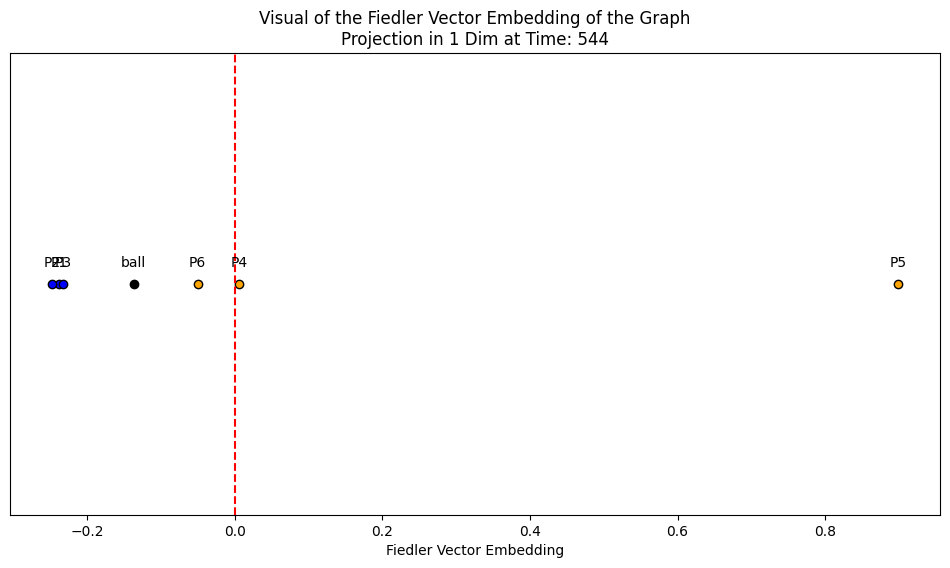

In [26]:
# random_time = np.random.randint(low=0, high=eigvec_df.shape[0])
random_time = 544
sample_time = eigvec_df.iloc[random_time, :]
labels = ['ball', 'P1', 'P2', 'P3', 'P4', 'P5', 'P6']

fig, ax = plt.subplots(figsize=(12,6))

for i, pos in enumerate(sample_time):
    if i == 0:
        color = 'black'
    elif i < 4:
        color = 'blue'
    else:
        color = 'orange'

    ax.scatter(x=pos, y=0, color=color, edgecolors='black')

# 3. Loop through data and add labels above the dots
for i, label in enumerate(labels):
    ax.annotate(
        label, 
        xy=(sample_time[i], 0),      # Target point coordinates
        textcoords="offset points",          # Use relative pixel offsets
        xytext=(0, 10),                      # (x, y) offset: 0 horizontally, 10 points above
        ha='center',                         # Centers text horizontally over the dot
        va='bottom',                         # Aligns the bottom of the text to the offset point
        color='black',                       # Force black text color
        fontsize=10
    )

plt.axvline(x=0, color='red', linestyle='--')
ax.yaxis.set_visible(False)
ax.set_xlabel('Fiedler Vector Embedding')
ax.set_title(f'Visual of the Fiedler Vector Embedding of the Graph\nProjection in 1 Dim at Time: {random_time}')
plt.show()

##### <center>Compare how often on average which team is closer to ball using real distances and spectral embedding<center>

In [27]:
dists_inds = [15, 24, 33, 42, 51, 60]

mean_dist_per_frame_blue = np.mean(sample_df.iloc[:, dists_inds].values[:, 0:3], axis=1)
mean_dist_per_frame_orange = np.mean(sample_df.iloc[:, dists_inds].values[:, 3:6], axis=1)
blue_team_state_dist = np.abs(team1_cluster - ball_state)
orange_team_state_dist = np.abs(team2_cluster - ball_state)

In [28]:
# 0: blue closer; 1: orange closer
real_dist_comp = np.select(condlist=[mean_dist_per_frame_blue < mean_dist_per_frame_orange, mean_dist_per_frame_blue > mean_dist_per_frame_orange],
                           choicelist=[0,1],
                           default=-1)
# 0: blue closer; 1: orange closer
spectral_embedding_comp = np.select(condlist=[blue_team_state_dist < orange_team_state_dist, blue_team_state_dist > orange_team_state_dist],
                           choicelist=[0,1],
                           default=-1)

In [29]:
print(f'mean value of `real_dist_comp`: {np.mean(real_dist_comp)}')
print(f'mean value of `spectral_embedding_comp`: {np.mean(spectral_embedding_comp)}')

mean value of `real_dist_comp`: 0.40441176470588236
mean value of `spectral_embedding_comp`: 0.3318014705882353


##### <center>Check percent of time each team is closer to the ball (real units and spectral embedding) when `hit_team_no` is their team<center>

In [30]:
real_dist_hit_team_df = pd.concat([pd.Series(real_dist_comp, name='real_dist_comp'), sample_df.hit_team_no], axis=1)
spectral_embedding_hit_team_df = pd.concat([pd.Series(spectral_embedding_comp, name='spectral_embedding_comp'), sample_df.hit_team_no], axis=1)

print(f'mean value of `real_dist_comp`, `hit_team_no` = 0: {real_dist_hit_team_df[real_dist_hit_team_df.hit_team_no == 0].real_dist_comp.mean()}')
print(f'mean value of `real_dist_comp`, `hit_team_no` = 1: {real_dist_hit_team_df[real_dist_hit_team_df.hit_team_no == 1].real_dist_comp.mean()}')

print(f'mean value of `spectral_embedding_comp`, `hit_team_no` = 0: {spectral_embedding_hit_team_df[spectral_embedding_hit_team_df.hit_team_no == 0].spectral_embedding_comp.mean()}')
print(f'mean value of `spectral_embedding_comp`, `hit_team_no` = 1: {spectral_embedding_hit_team_df[spectral_embedding_hit_team_df.hit_team_no == 1].spectral_embedding_comp.mean()}')

mean value of `real_dist_comp`, `hit_team_no` = 0: 0.30638297872340425
mean value of `real_dist_comp`, `hit_team_no` = 1: 0.47085201793721976
mean value of `spectral_embedding_comp`, `hit_team_no` = 0: 0.2957446808510638
mean value of `spectral_embedding_comp`, `hit_team_no` = 1: 0.34080717488789236


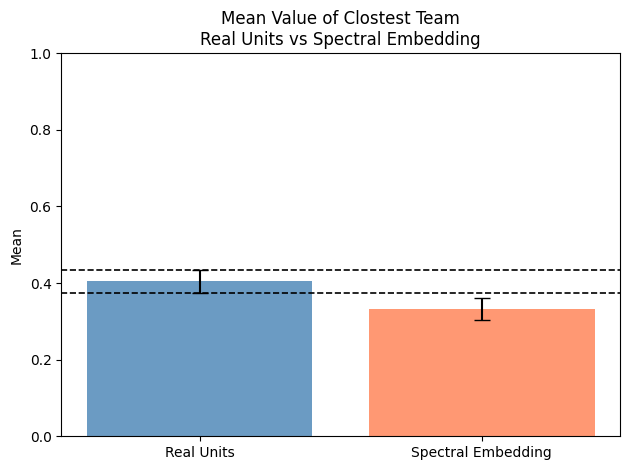

In [37]:
"""
Make a bar plot comparing the mean values above with 95% confidence bars
"""
def mean_ci95(arr):
    n = len(arr)
    return arr.mean(), 1.96 * arr.std() / np.sqrt(n)

mean_a, ci_a = mean_ci95(real_dist_comp)
mean_b, ci_b = mean_ci95(spectral_embedding_comp)

# --- Plot ---
labels = ['Real Units', 'Spectral Embedding']
means  = [mean_a, mean_b]
cis    = [ci_a, ci_b]

fig, ax = plt.subplots()
bars = ax.bar(labels, means, yerr=cis, capsize=6,
              color=['steelblue', 'coral'], alpha=0.8,
              error_kw=dict(elinewidth=1.5, ecolor='black'))

ax.axhline(mean_a + ci_a, color='black', linestyle='dashed', linewidth=1.2)
ax.axhline(mean_a - ci_a, color='black', linestyle='dashed', linewidth=1.2)

ax.set_ylim(0,1)
ax.set_ylabel('Mean')
ax.set_title('Mean Value of Clostest Team\nReal Units vs Spectral Embedding')
plt.tight_layout()
plt.show()

In [32]:
ones_real = [i for i in real_dist_comp if i == 1]
zeros_real = [i for i in real_dist_comp if i == 0]

ones_spectral = [i for i in spectral_embedding_comp if i == 1]
zeros_spectral = [i for i in spectral_embedding_comp if i == 0]

print(f'Ones comparison: real - {len(ones_real)} | spectral - {len(ones_spectral)}')
print(f'Zeros comparison: real - {len(zeros_real)} | spectral - {len(zeros_spectral)}')

Ones comparison: real - 440 | spectral - 361
Zeros comparison: real - 648 | spectral - 727


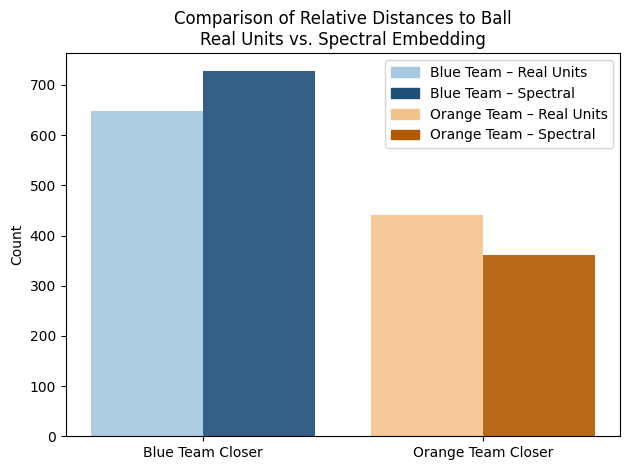

In [33]:
"""
Make a bar plot comparing the counts
"""

labels_group = ['Blue Team Closer', 'Orange Team Closer']
x = np.arange(len(labels_group))
width = 0.4

# Each group now holds [Real Units count, Spectral Embedding count]
counts_blue   = [len(zeros_real), len(zeros_spectral)]
counts_orange = [len(ones_real),  len(ones_spectral)]

# Values per x position (Blue group, Orange group), split by model
real_vals     = [counts_blue[0], counts_orange[0]]
spectral_vals = [counts_blue[1], counts_orange[1]]

fig, ax = plt.subplots()

# Blue group: light/dark blue
ax.bar(x[0] - width/2, real_vals[0],     width, color='#a6c8e0', alpha=0.9)
ax.bar(x[0] + width/2, spectral_vals[0], width, color='#1f4e79', alpha=0.9)

# Orange group: light/dark orange
ax.bar(x[1] - width/2, real_vals[1],     width, color='#f4c28c', alpha=0.9)
ax.bar(x[1] + width/2, spectral_vals[1], width, color='#b35900', alpha=0.9)

ax.set_xticks(x)
ax.set_xticklabels(labels_group)
ax.set_ylabel('Count')
ax.set_title('Comparison of Relative Distances to Ball\nReal Units vs. Spectral Embedding')

# Manual legend since colors differ per group
import matplotlib.patches as mpatches
legend_elements = [
    mpatches.Patch(color='#a6c8e0', label='Blue Team – Real Units'),
    mpatches.Patch(color='#1f4e79', label='Blue Team – Spectral'),
    mpatches.Patch(color='#f4c28c', label='Orange Team – Real Units'),
    mpatches.Patch(color='#b35900', label='Orange Team – Spectral'),
]
ax.legend(handles=legend_elements)

plt.tight_layout()
plt.show()

### <center>Checking the Spectral decay of the graph laplacians<center>

Spectral Decay $:= \lambda_k/\lambda_1$ for all $k$ eigenvectors

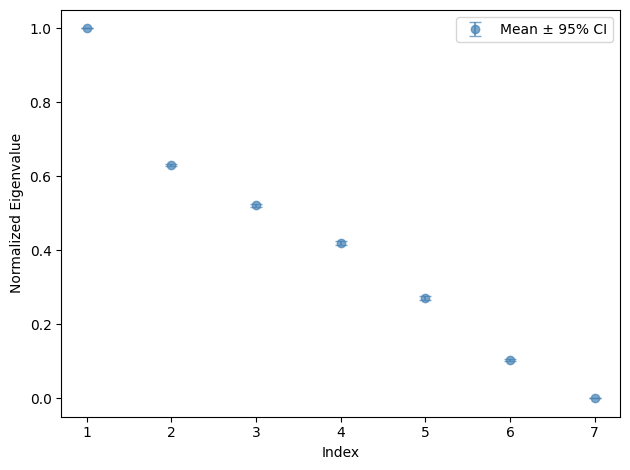

In [34]:
"""
make this a line graph with 95% confidence bounds
"""
eigenvalues = []
for L in laplacians:
    eigvalues, _ = np.linalg.eigh(L)
    eigenvalues.append(np.sort(eigvalues)[::-1])

normalized = np.array([vals / max(vals) for vals in eigenvalues])

mean_vals = normalized.mean(axis=0)
std_vals  = normalized.std(axis=0)
n         = len(eigenvalues)
ci95      = 1.96 * std_vals / np.sqrt(n)

x = np.arange(normalized.shape[1])

plt.errorbar(x+1, mean_vals, yerr=ci95,
             fmt='o',           # circle markers, no line
             capsize=4,         # horizontal caps on error bars
             color='steelblue',
             ecolor='steelblue',
             alpha=0.7,
             label='Mean ± 95% CI')

plt.xlabel('Index')
plt.ylabel('Normalized Eigenvalue')
plt.legend()
plt.tight_layout()
plt.show()